In [1]:
# construct figures for monochromatic psf fisher information

import jax
import jax.numpy as np
import dLux as dl
import dLux.utils as dlu
import matplotlib.pyplot as plt
from matplotlib.style import use
use('default')
jax.config.update("jax_enable_x64", True)
plt.rcParams['image.origin'] = 'lower'

from jax.scipy.special import gammaln, xlogy

def poisson_loglike_gamma(k, mu):
    # analytic continuation using gammaln(k+1)
    k = np.asarray(k, dtype=float)
    mu = np.asarray(mu, dtype=float)
    valid = (k >= 0) & np.isfinite(k) & (mu > 0) & np.isfinite(mu)
    logp = xlogy(k, mu) - mu - gammaln(k + 1.0)
    return np.where(valid, logp, -np.inf)

In [2]:
diameter = 1.0
wavelength = 1e-6

flux = 1e6 # just a simply large number

source = dl.PointSource(position = np.zeros(2), flux=flux, wavelengths=np.array([wavelength]))

Nyq_factor = 4 # 4x oversample nyquist

# generate a very well sampled circle methinks
wf_npix = 2048
wf_oversample = 5

aperture = dlu.circular_aperture(wf_npix, diameter, wf_oversample)

layers = [
    (
        'aperture',
        dl.TransmissiveLayer(aperture, normalise=True)
    )
]

rmax = 10 # units lambda/D

fov = 2*wavelength/diameter*rmax # fov in radians. not radial, whole fov

psf_npix = int(np.ceil(2 * (2 * rmax) * Nyq_factor))

psf_pixel_scale = dlu.rad2arcsec(fov/psf_npix)

optics = dl.AngularOpticalSystem(
    wf_npix,
    diameter,
    layers,
    psf_npix,
    psf_pixel_scale,
    1
)

telescope = dl.Telescope(optics, source)

data = telescope.model()

In [3]:
# let us calculate fisher first.. then think about circular mask
from zodiax.diffops import hessian
def loss_fn(params, model, data):
    model = model.set(params)
    img = model.model()

    ny, nx = data.shape
    y, x = np.indices(data.shape)

    mask = (x - (nx - 1) / 2)**2 + (y - (ny - 1) / 2)**2 <= (min(nx, ny) / 2)**2

    loss = -np.where(mask, poisson_loglike_gamma(data, img), 0.0).sum()

    # loss = -poisson_loglike_gamma(data, img).sum()
    return loss

params = {
    'wavelengths':
    np.array([wavelength])
}

f = lambda params: loss_fn(params, telescope, data)

H, unflatten = hessian(f, params)

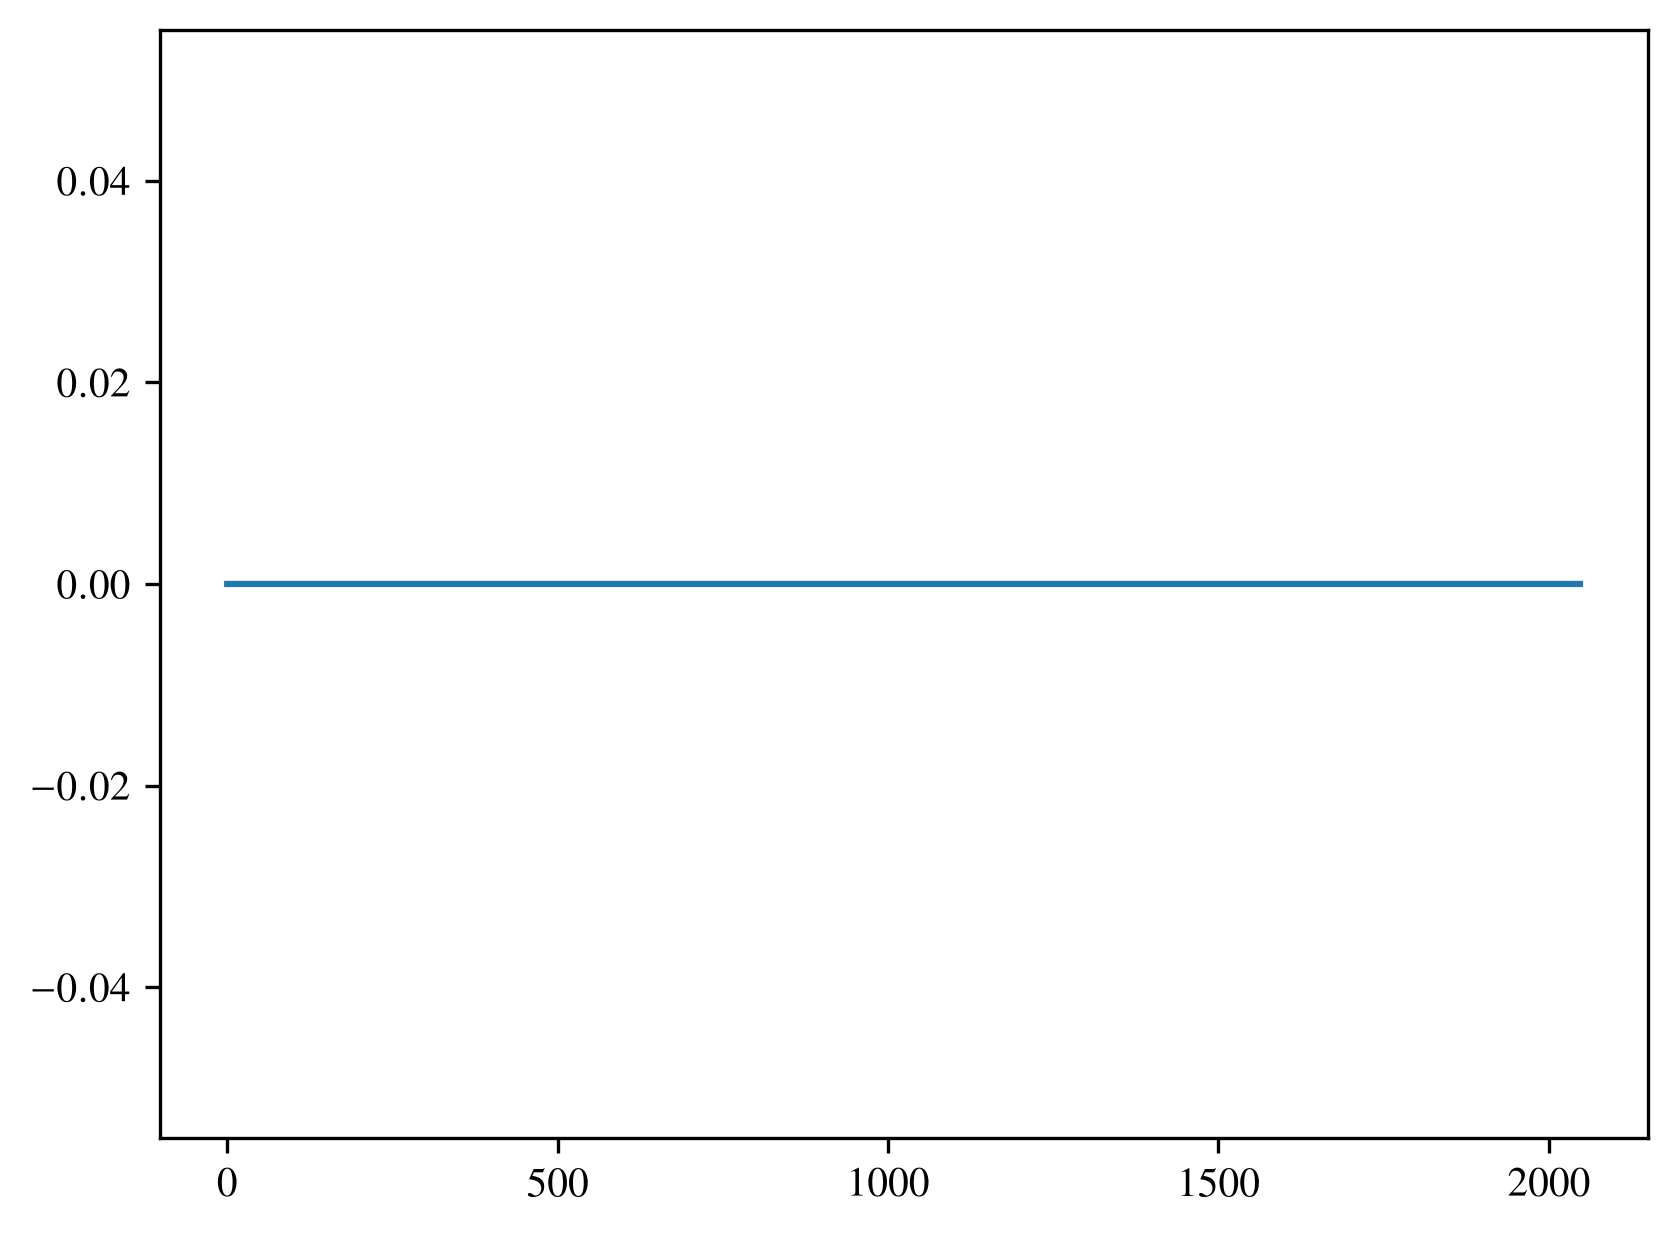

In [30]:
plt.plot(square[0,:])

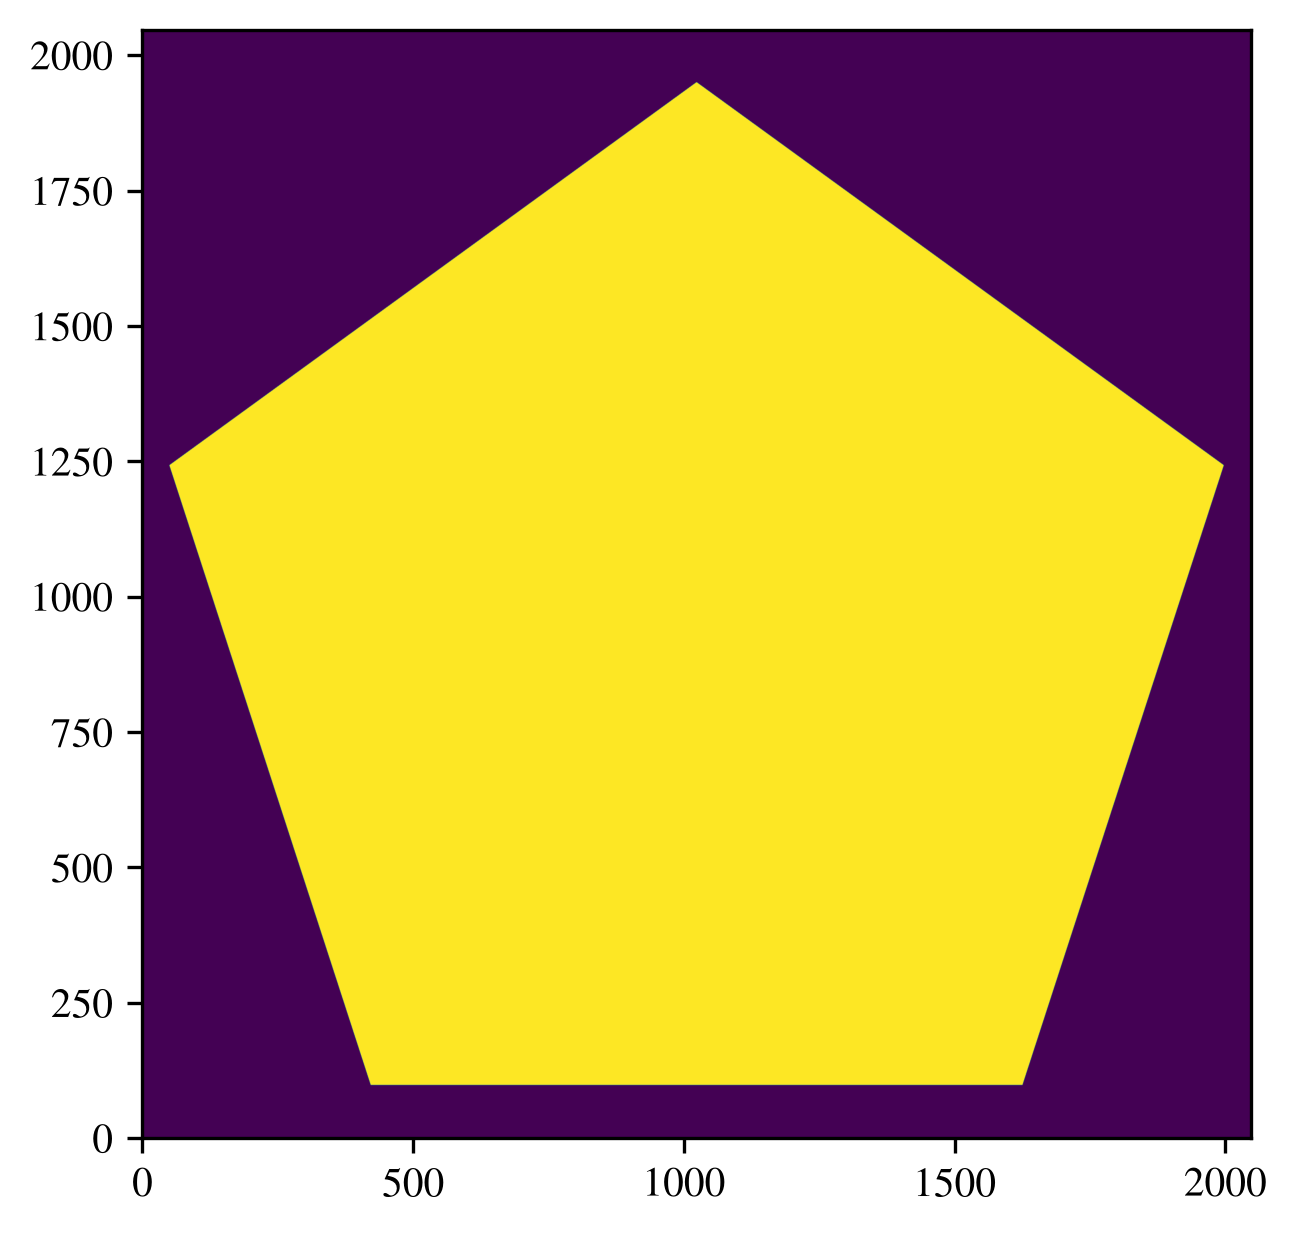

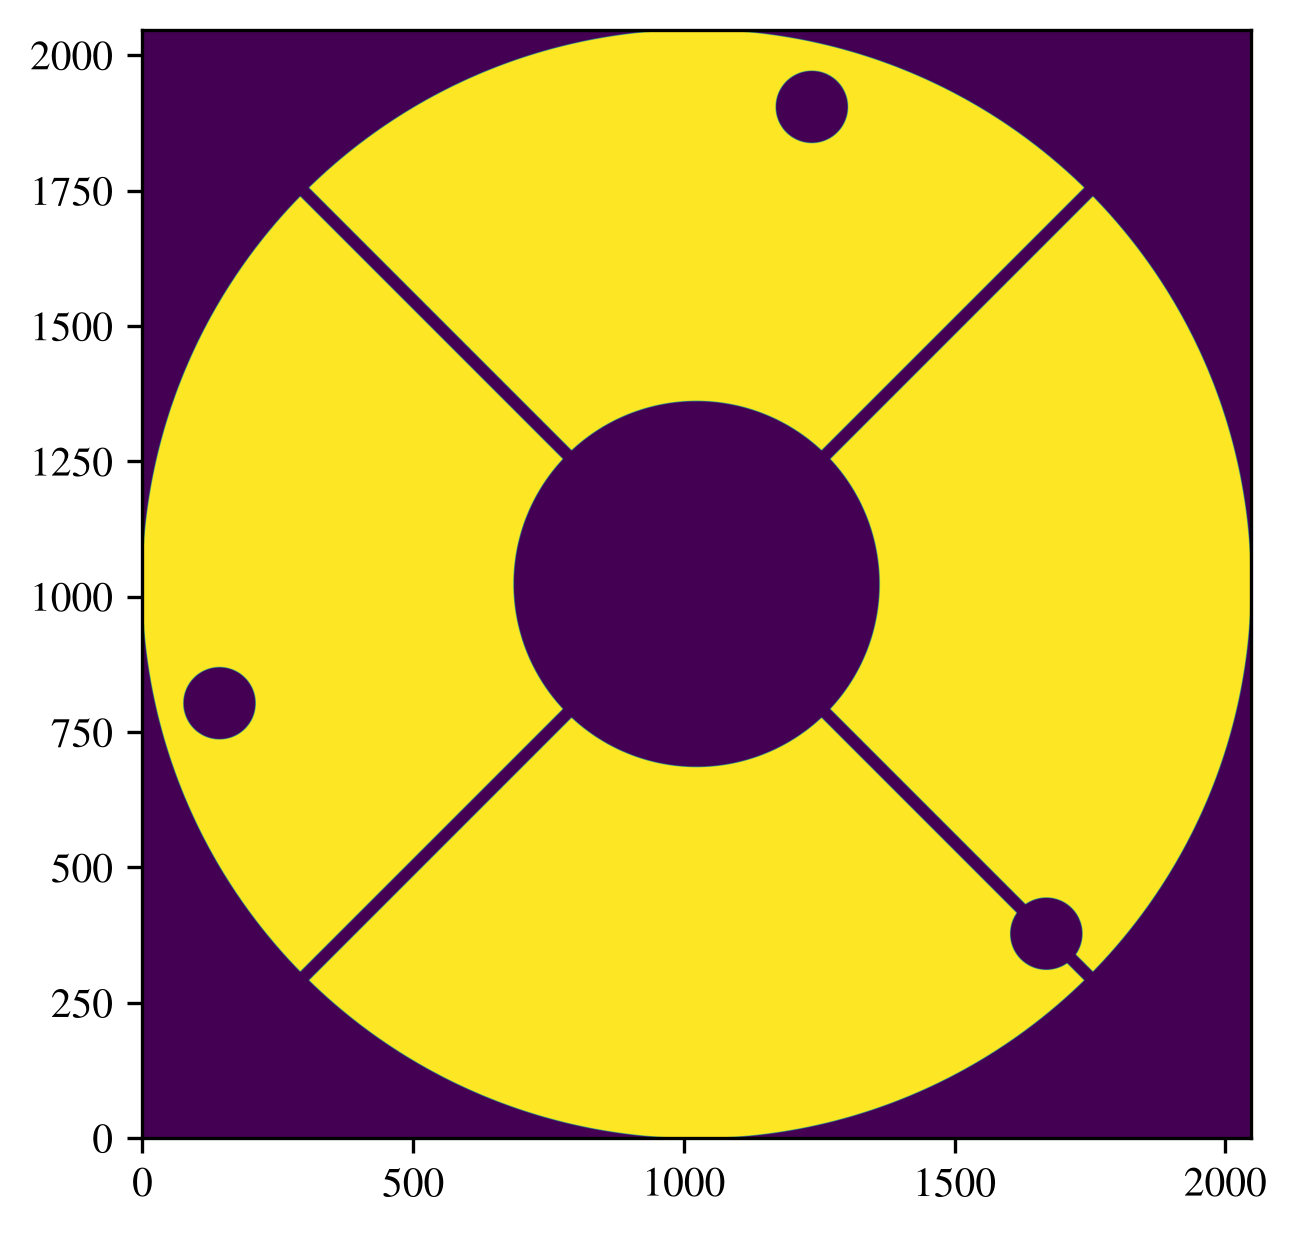

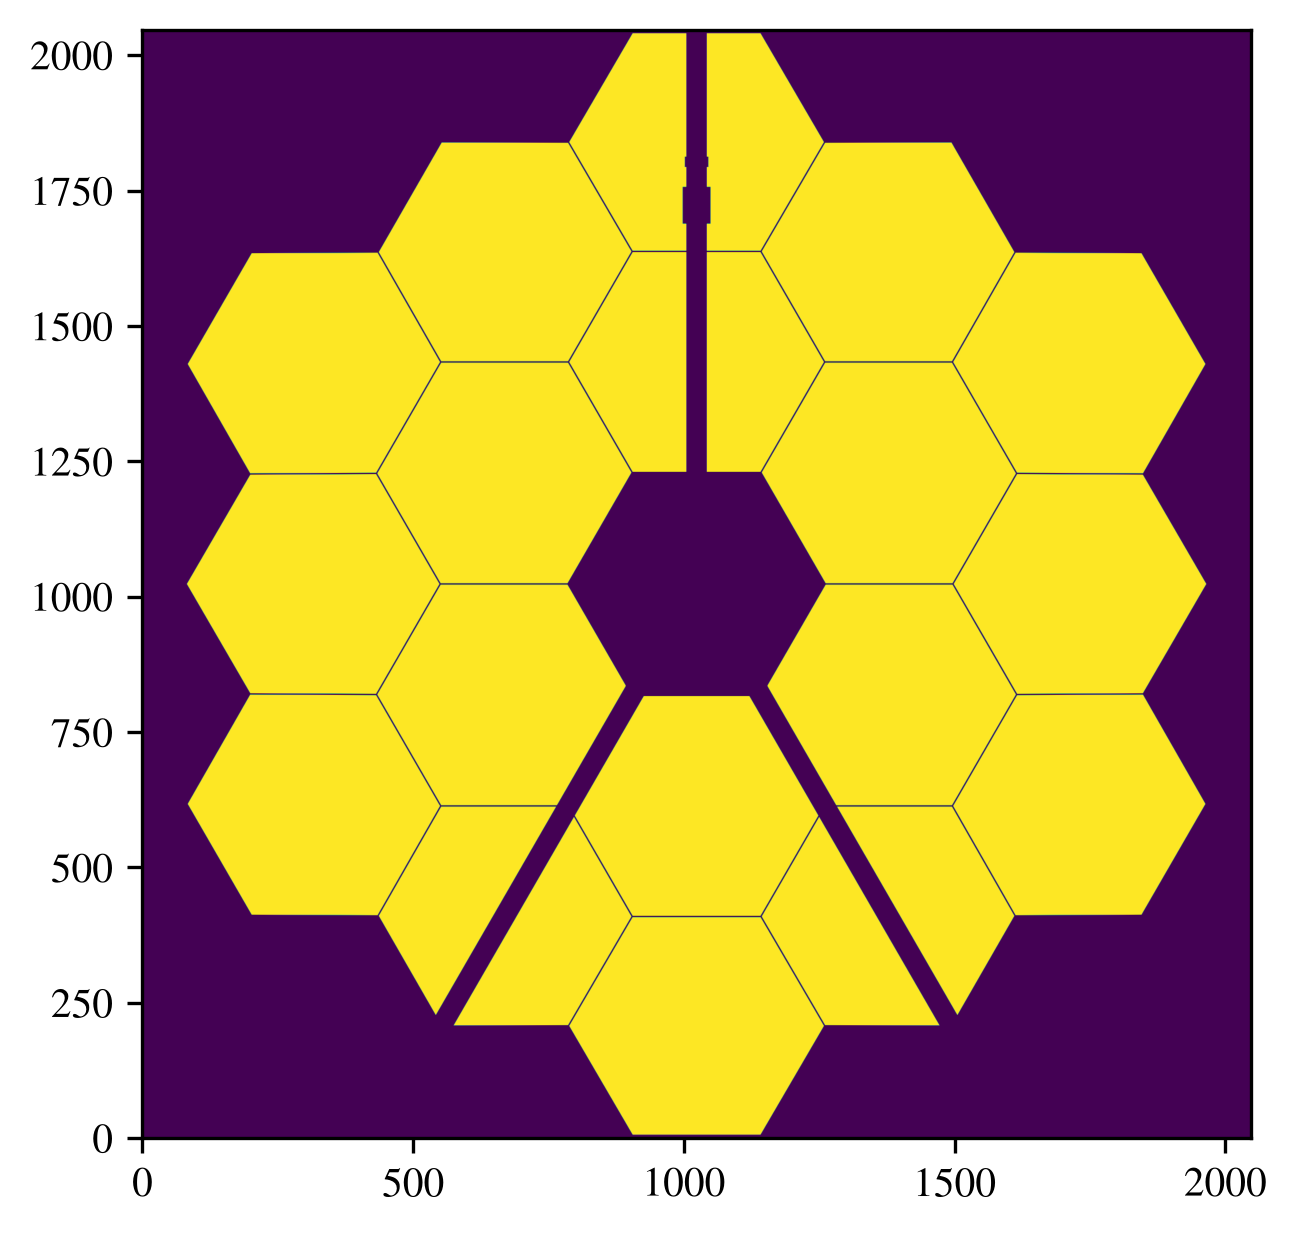

In [45]:
coords = dlu.pixel_coords(wf_npix*wf_oversample, diameter)

square = (dlu.downsample(dlu.reg_polygon(coords, diameter/2, 5), wf_oversample, mean=True).T)[::-1,:]

# just putting in a nicer spot
tol = 1e-12

mask = np.any(np.abs(square) > tol, axis=1)  # True for rows with any nonzero element

nzero = len(square) if not mask.any() else np.argmax(mask)
half = nzero // 2

square = np.concatenate([square[half:], square[:half]], axis=0)


layers_square = [
    (
        'aperture',
        dl.TransmissiveLayer(square, normalise=True)
    )
]

# try webb and hst apertures I thinik
wfc3 = np.load('wfc3_aperture_2048.npy')
layers_wfc3 = [
    (
        'aperture',
        dl.TransmissiveLayer(wfc3, normalise=True)
    )
]

nircam = np.load('nircam_aperture_2048.npy')

layers_nircam = [
    (
        'aperture',
        dl.TransmissiveLayer(nircam, normalise=True)
    )
]

plt.imshow(square)
plt.show()

plt.imshow(wfc3)
plt.show()

plt.imshow(nircam)
plt.show()

In [46]:
# ok so that works. now for different values of rmax
rmaxes = np.logspace(0, 2, 100)

Hs_airy = []
Hs_square = []
Hs_wfc3 = []
Hs_nircam = []

for rmax in rmaxes:
    print(rmax)
    fov = 2*wavelength/diameter*rmax # fov in radians. not radial, whole fov

    psf_npix = int(np.ceil(2 * (2 * rmax) * Nyq_factor))

    psf_pixel_scale = dlu.rad2arcsec(fov/psf_npix)

    optics = dl.AngularOpticalSystem(
        wf_npix,
        diameter,
        layers,
        psf_npix,
        psf_pixel_scale,
        1
    )

    telescope = dl.Telescope(optics, source)

    data = telescope.model()
    f = lambda params: loss_fn(params, telescope, data)
    H, unflatten = hessian(f, params)
    H = H.squeeze()
    Hs_airy.append(H)

    # SQUARE STUFF
    optics_square = dl.AngularOpticalSystem(
        wf_npix,
        diameter,
        layers_square,
        psf_npix,
        psf_pixel_scale,
        1
    )

    telescope_square = dl.Telescope(optics_square, source)

    data = telescope_square.model()
    f = lambda params: loss_fn(params, telescope_square, data)
    H, unflatten = hessian(f, params)
    H = H.squeeze()
    Hs_square.append(H)

    # HUBBLE STUFF
    optics_wfc3 = dl.AngularOpticalSystem(
        wf_npix,
        diameter,
        layers_wfc3,
        psf_npix,
        psf_pixel_scale,
        1
    )

    telescope_wfc3 = dl.Telescope(optics_wfc3, source)

    data = telescope_wfc3.model()
    f = lambda params: loss_fn(params, telescope_wfc3, data)
    H, unflatten = hessian(f, params)
    H = H.squeeze()
    Hs_wfc3.append(H)

    # NIRCAM STUFF
    optics_nircam = dl.AngularOpticalSystem(
        wf_npix,
        diameter,
        layers_nircam,
        psf_npix,
        psf_pixel_scale,
        1
    )

    telescope_nircam = dl.Telescope(optics_nircam, source)

    data = telescope_nircam.model()
    f = lambda params: loss_fn(params, telescope_nircam, data)
    H, unflatten = hessian(f, params)
    H = H.squeeze()
    Hs_nircam.append(H)


1.0
1.0476157527896648
1.0974987654930561
1.1497569953977358
1.2045035402587823
1.2618568830660204
1.321941148466029
1.384886371393873
1.4508287784959397
1.5199110829529336
1.5922827933410924
1.6681005372000588
1.7475284000076838
1.8307382802953682
1.9179102616724888
2.0092330025650473
2.1049041445120205
2.205130739903046
2.3101297000831598
2.420128264794382
2.535364493970112
2.6560877829466865
2.782559402207125
2.915053062825177
3.0538555088334154
3.1992671377973836
3.3516026509388426
3.511191734215132
3.6783797718286344
3.8535285937105295
4.0370172585965545
4.229242874389499
4.430621457583881
4.641588833612779
4.862601580065355
5.09413801481638
5.3366992312063095
5.590810182512224
5.857020818056667
6.135907273413174
6.428073117284322
6.734150657750823
7.054802310718643
7.390722033525779
7.742636826811272
8.111308307896872
8.497534359086444
8.902150854450388
9.326033468832199
9.770099572992255
10.235310218990262
10.722672220103236
11.233240329780276
11.768119524349984
12.3284673944206

In [47]:
# defining analytic result
def wl_fisher_airy(wavelength, flux, diameter, R):
    fisher = 8*flux*diameter*R/(wavelength**3)
    return fisher

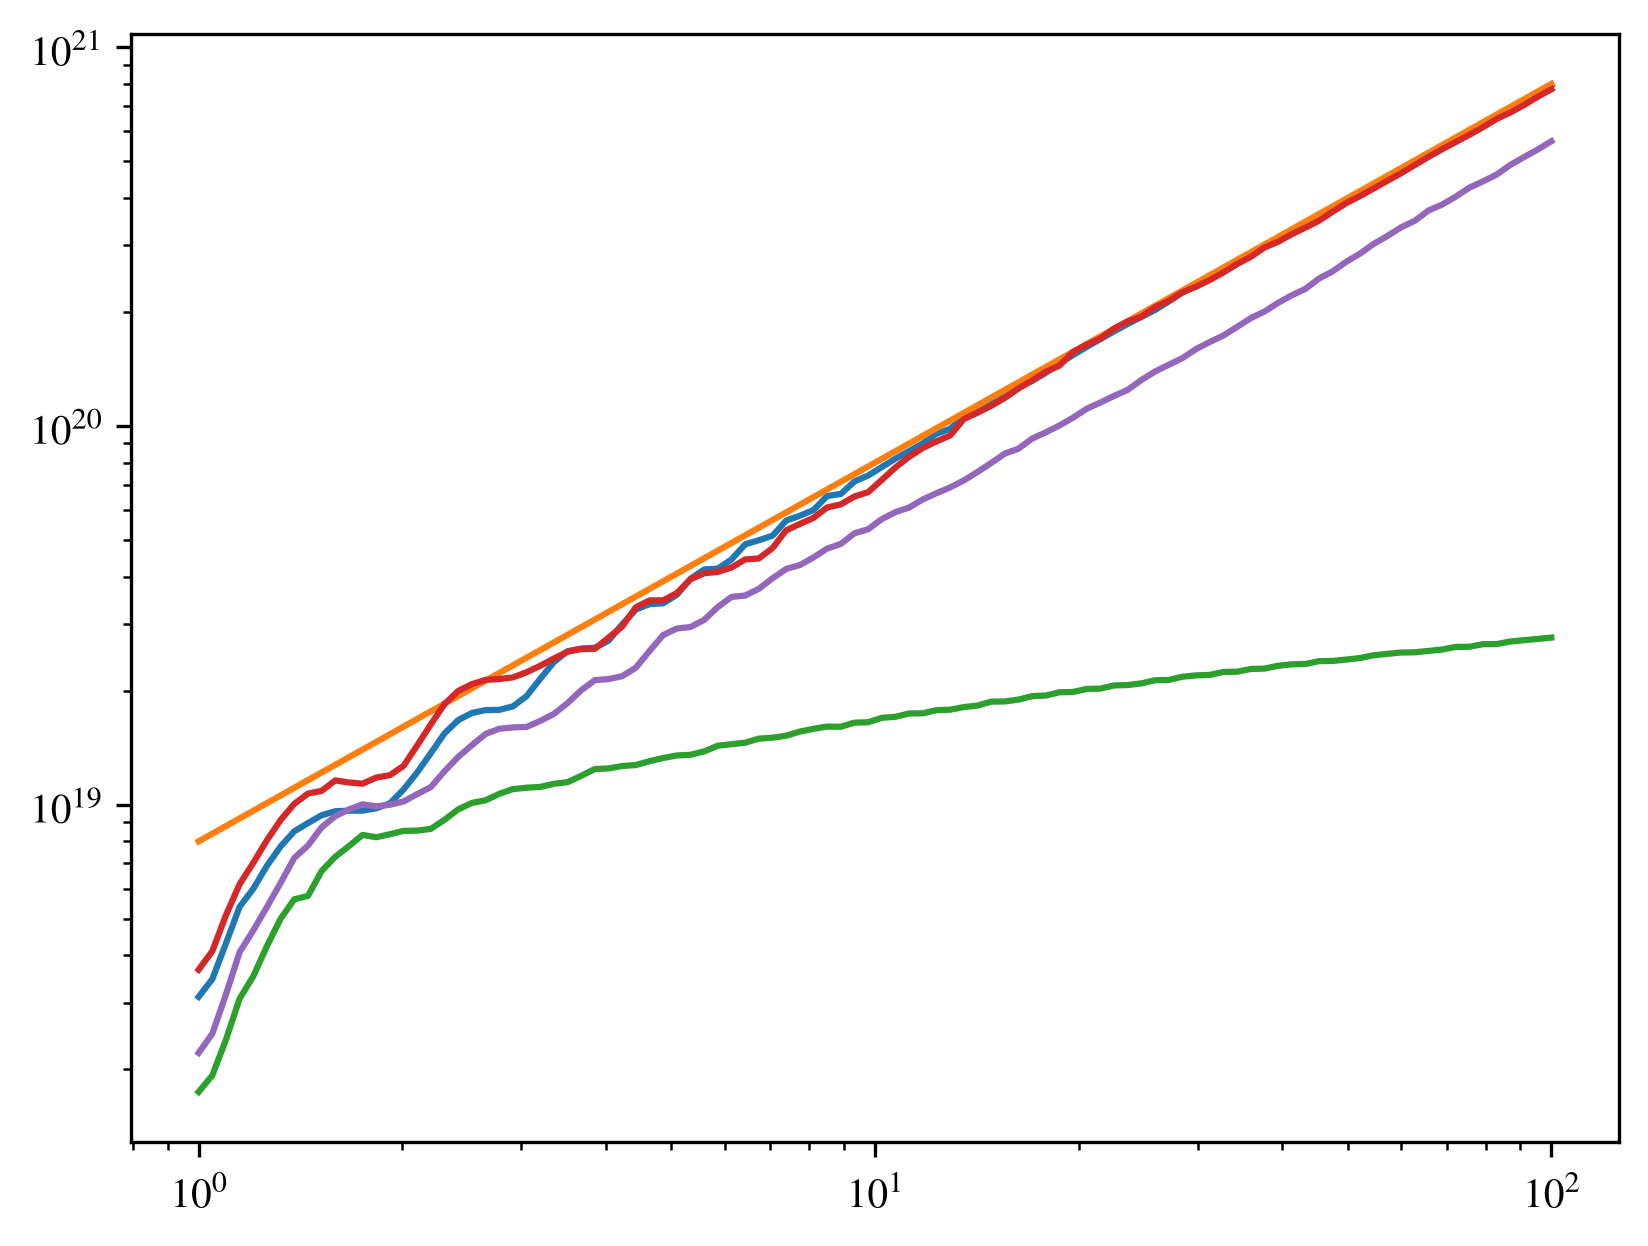

In [48]:
plt.loglog(rmaxes, Hs_airy)
plt.loglog(rmaxes, wl_fisher_airy(wavelength, flux, diameter, rmaxes*wavelength/diameter))
plt.loglog(rmaxes, Hs_square)
plt.loglog(rmaxes, Hs_wfc3)
plt.loglog(rmaxes, Hs_nircam)
plt.show()

/Library/TeX/texbin/latex


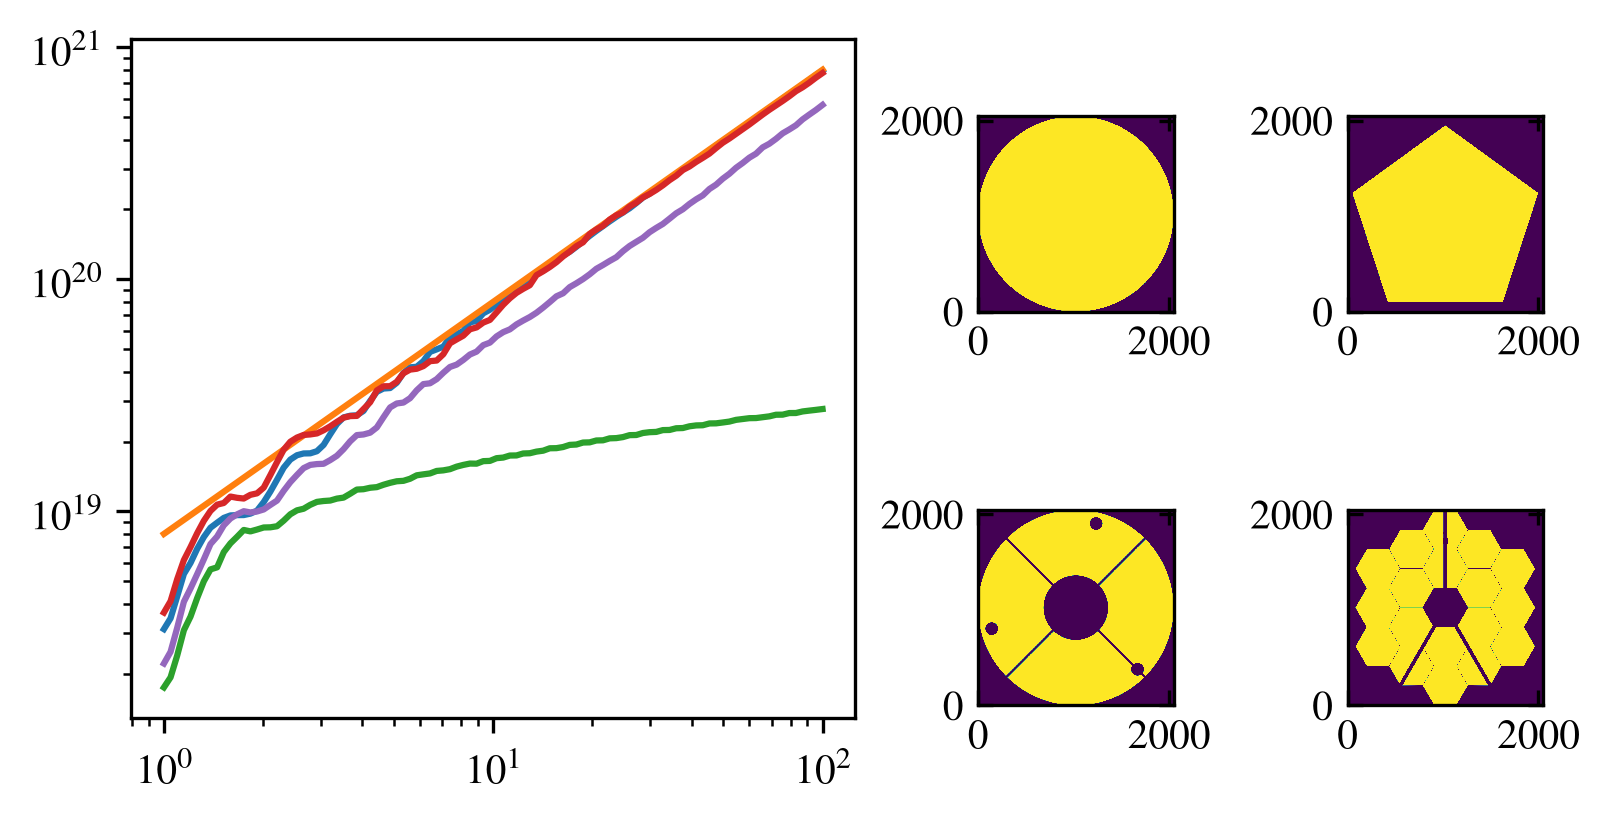

In [49]:
# latex
import os
os.environ["PATH"] = "/Library/TeX/texbin:" + os.environ["PATH"]
import shutil
print(shutil.which("latex"))

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "text.latex.preamble": r"""
\usepackage[T1]{fontenc}
\usepackage{newtxtext,newtxmath}
""",

    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.titlesize": 10,
})

plt.rcParams["figure.dpi"] = 300
# fig_width = 379.41753 / 72.27 # = 5.25
fig_width = 5.25

fig = plt.figure(
    figsize=(fig_width, 0.5 * fig_width),
    constrained_layout=True,
)

# Outer layout: large line plot + right-hand image block
outer = fig.add_gridspec(
    1, 2,
    width_ratios=[1, 1],
)

ax = fig.add_subplot(outer[0, 0])

# Divide the right-hand side into four square panels
right = outer[0, 1].subgridspec(
    2, 2,
    wspace=0.05,
    hspace=0.05,
)

ax_im1 = fig.add_subplot(right[0, 0])
ax_im2 = fig.add_subplot(right[0, 1])
ax_im3 = fig.add_subplot(right[1, 0])
ax_im4 = fig.add_subplot(right[1, 1])

# Left panel
# ax.loglog(x, y)
ax.loglog(rmaxes, Hs_airy)
ax.loglog(rmaxes, wl_fisher_airy(wavelength, flux, diameter, rmaxes*wavelength/diameter))
ax.loglog(rmaxes, Hs_square)
ax.loglog(rmaxes, Hs_wfc3)
ax.loglog(rmaxes, Hs_nircam)

# Right panels
image_axes = [ax_im1, ax_im2, ax_im3, ax_im4]
arrays = [aperture, square, wfc3, nircam]

for ax_im, array in zip(image_axes, arrays):
    ax_im.imshow(
        array,
        origin="lower",
        interpolation="none",
        aspect="equal",
    )
    ax_im.set_box_aspect(1)  # makes the axes themselves square
    ax_im.tick_params(
        axis="both",
        which="both",
        direction="in",
        top=True,
        right=True,
    )

In [50]:
Hs_analytic = wl_fisher_airy(wavelength, flux, diameter, rmaxes*wavelength/diameter)

In [51]:
dimless_fac = wavelength**2/flux

In [52]:
dimless_fac

1e-18

In [53]:
rmaxes_analytic = np.logspace(-0.2, 2.2, 5)
Hs_analytic = wl_fisher_airy(wavelength, flux, diameter, rmaxes_analytic*wavelength/diameter)

In [54]:
vmin

-3.0

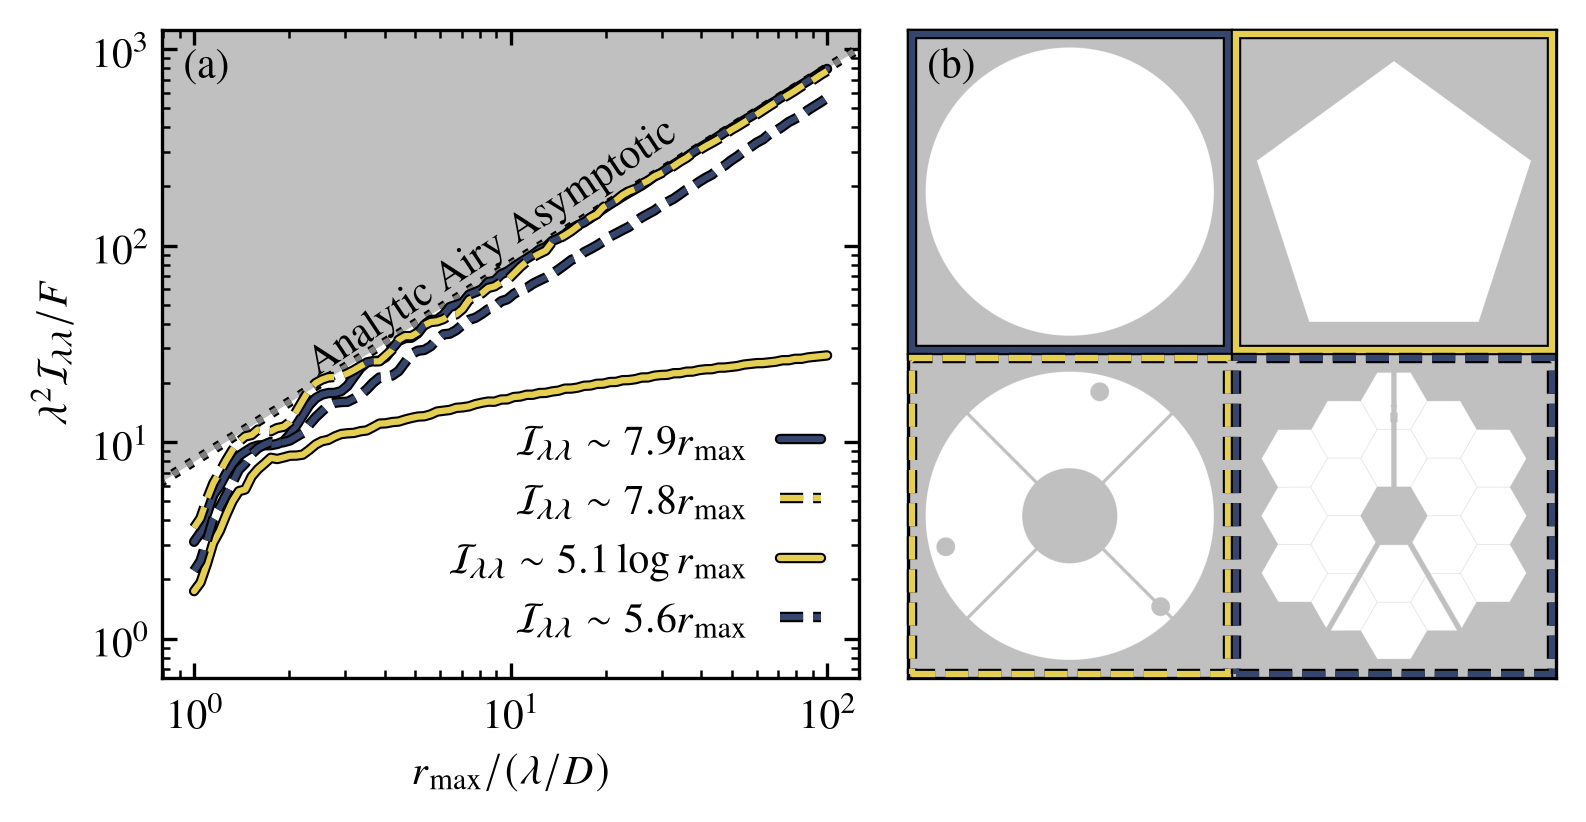

In [58]:
import matplotlib.patheffects as pe
import numpy as onp

path_effects = [
    pe.Stroke(linewidth=2.5, foreground="k"),
    pe.Normal(),
]

cmap = plt.colormaps['cividis']
color_1 = cmap(0.2)
color_2 = cmap(0.9)

vmax = 1.0
u0 = 0.75 # zero will use gray-cmap value at 75%

vmin = -(u0 / (1 - u0)) * vmax
zero_gray = plt.colormaps["gray"](u0)

border_pad = 128  # border width in pixels

wfc3_pad, nircam_pad, aperture_pad, square_pad = [
    np.pad(a, border_pad, constant_values=0)
    for a in (wfc3, nircam, aperture, square)
]

combined = np.block([
    [wfc3_pad, nircam_pad],
    [aperture_pad, square_pad],
])

fig, (ax, ax_im) = plt.subplots(
    1, 2,
    figsize=(fig_width, 0.5 * fig_width),
    gridspec_kw={"width_ratios": [1, 1]},
    constrained_layout=True,
)

ys_analytic = np.array(Hs_analytic)*dimless_fac
ys_airy = np.array(Hs_airy)*dimless_fac
ys_square = np.array(Hs_square)*dimless_fac
ys_wfc3 = np.array(Hs_wfc3)*dimless_fac
ys_nircam = np.array(Hs_nircam)*dimless_fac

ax.loglog(rmaxes_analytic, ys_analytic,
          path_effects=path_effects, ls=':',
          color='0.5')
ax.loglog(rmaxes, ys_airy,
          path_effects=path_effects,
          color=color_1, label=r'$\mathcal{I}_{\lambda \lambda} \sim 7.9 r_{\max}$', solid_capstyle='round')
ax.loglog(rmaxes, ys_wfc3,
          path_effects=path_effects,
          color=color_2, ls='--', label=r'$\mathcal{I}_{\lambda \lambda} \sim 7.8 r_{\max}$')
ax.loglog(rmaxes, ys_square,
          path_effects=path_effects,
          color=color_2, label=r'$\mathcal{I}_{\lambda \lambda} \sim 5.1 \log r_{\max}$', solid_capstyle='round')
ax.loglog(rmaxes, ys_nircam,
          path_effects=path_effects,
          color=color_1, ls='--', label=r'$\mathcal{I}_{\lambda \lambda} \sim 5.6 r_{\max}$')

ax.fill_between(
    rmaxes_analytic,
    ys_analytic,
    ax.get_ylim()[1],
    color=zero_gray,
    alpha=1.0,
    linewidth=0,
    zorder=0,
)

ax.tick_params(axis='both',
               which='both',
               direction='in',
               top=True,
               right=True)

ax.set_ylim(10**(-0.2), 10**3.1)
ax.set_xlim(10**(-0.1), 10**2.1)

ax.set_xlabel(r'$r_{\max}/(\lambda/D)$')
ax.set_ylabel(r'$\lambda^2 \mathcal{I}_{\lambda \lambda}/F$')

ax.text(
    0.03, 0.97,
    r'(a)',
    transform=ax.transAxes,
    ha='left',
    va='top',
    color='k'
)

ax.text(
    0.2, 0.87,
    r'Analytic Airy Asymptotic',
    transform=ax.transAxes,
    ha='left',
    va='top',
    color='k',
    rotation=33.5,
)

ax.legend(frameon=False, markerfirst=False, handlelength=1.0)

ax_im.imshow(
    combined,
    origin="lower",
    aspect="equal",
    interpolation="auto",
    cmap='gray',
    vmin=vmin,
    vmax=vmax
)

ax_im.text(
    0.03, 0.97,
    r'(b)',
    transform=ax_im.transAxes,
    ha='left',
    va='top',
    color='k'
)

ax_im.set_xticks([])
ax_im.set_yticks([])

from matplotlib.patches import Rectangle

pad = 0.00644 # in axes-fraction units

path_effects_thick = [
    pe.Stroke(linewidth=2.5, foreground="k"),
    pe.Normal(),
]

rect_kw = dict(
    fill=False,
    lw=1.5,
    transform=ax_im.transAxes,
    clip_on=False,
    zorder=10,
    path_effects=path_effects_thick,
    # capstyle='round',
)

# In the displayed image:
# top-left  = aperture   -> Airy      -> color_1, solid
# top-right = square     -> square    -> color_2, solid
# bottom-left = wfc3     -> WFC3      -> color_2, dashed
# bottom-right = nircam  -> NIRCam    -> color_1, dashed

ax_im.add_patch(Rectangle(
    (0.00 + pad, 0.50 + pad), 0.50 - 2*pad, 0.50 - 2*pad,
    edgecolor=color_1, linestyle='-', **rect_kw
))

ax_im.add_patch(Rectangle(
    (0.50 + pad, 0.50 + pad), 0.50 - 2*pad, 0.50 - 2*pad,
    edgecolor=color_2, linestyle='-', **rect_kw
))

ax_im.add_patch(Rectangle(
    (0.00 + pad, 0.00 + pad), 0.50 - 2*pad, 0.50 - 2*pad,
    edgecolor=color_2, linestyle='--', **rect_kw
))

ax_im.add_patch(Rectangle(
    (0.50 + pad, 0.00 + pad), 0.50 - 2*pad, 0.50 - 2*pad,
    edgecolor=color_1, linestyle='--', **rect_kw
))

# plt.savefig('monofigureF.png', dpi=300)
plt.show()

In [ ]:
plt.rcParams['lines.dash_joinstyle'] = 'round'

In [326]:
ys_airy

Array([  3.10959723,   4.32003399,   6.03285936,   7.8039144 ,
         8.98165914,   9.61746021,   9.65237139,  10.1570896 ,
        12.41073068,  15.41586332,  17.56673205,  17.82907427,
        19.92940046,  24.31605288,  25.84383653,  27.95671779,
        33.2464402 ,  34.31699102,  40.72581175,  42.45309161,
        49.65987768,  53.34409716,  58.14157748,  65.94440481,
        73.58159714,  81.16603994,  89.41745646,  97.9324332 ,
       106.15455124, 118.35524338, 129.99566805, 144.55478219,
       157.85236834, 173.7750579 , 192.55705688, 210.03350353,
       233.06949053, 255.95184299, 281.69282399, 307.3958237 ,
       338.19160867, 372.3757292 , 409.85374689, 449.94678834,
       497.00142281, 545.49939935, 599.98185507, 657.17395629,
       721.74892961, 793.03657055], dtype=float64)

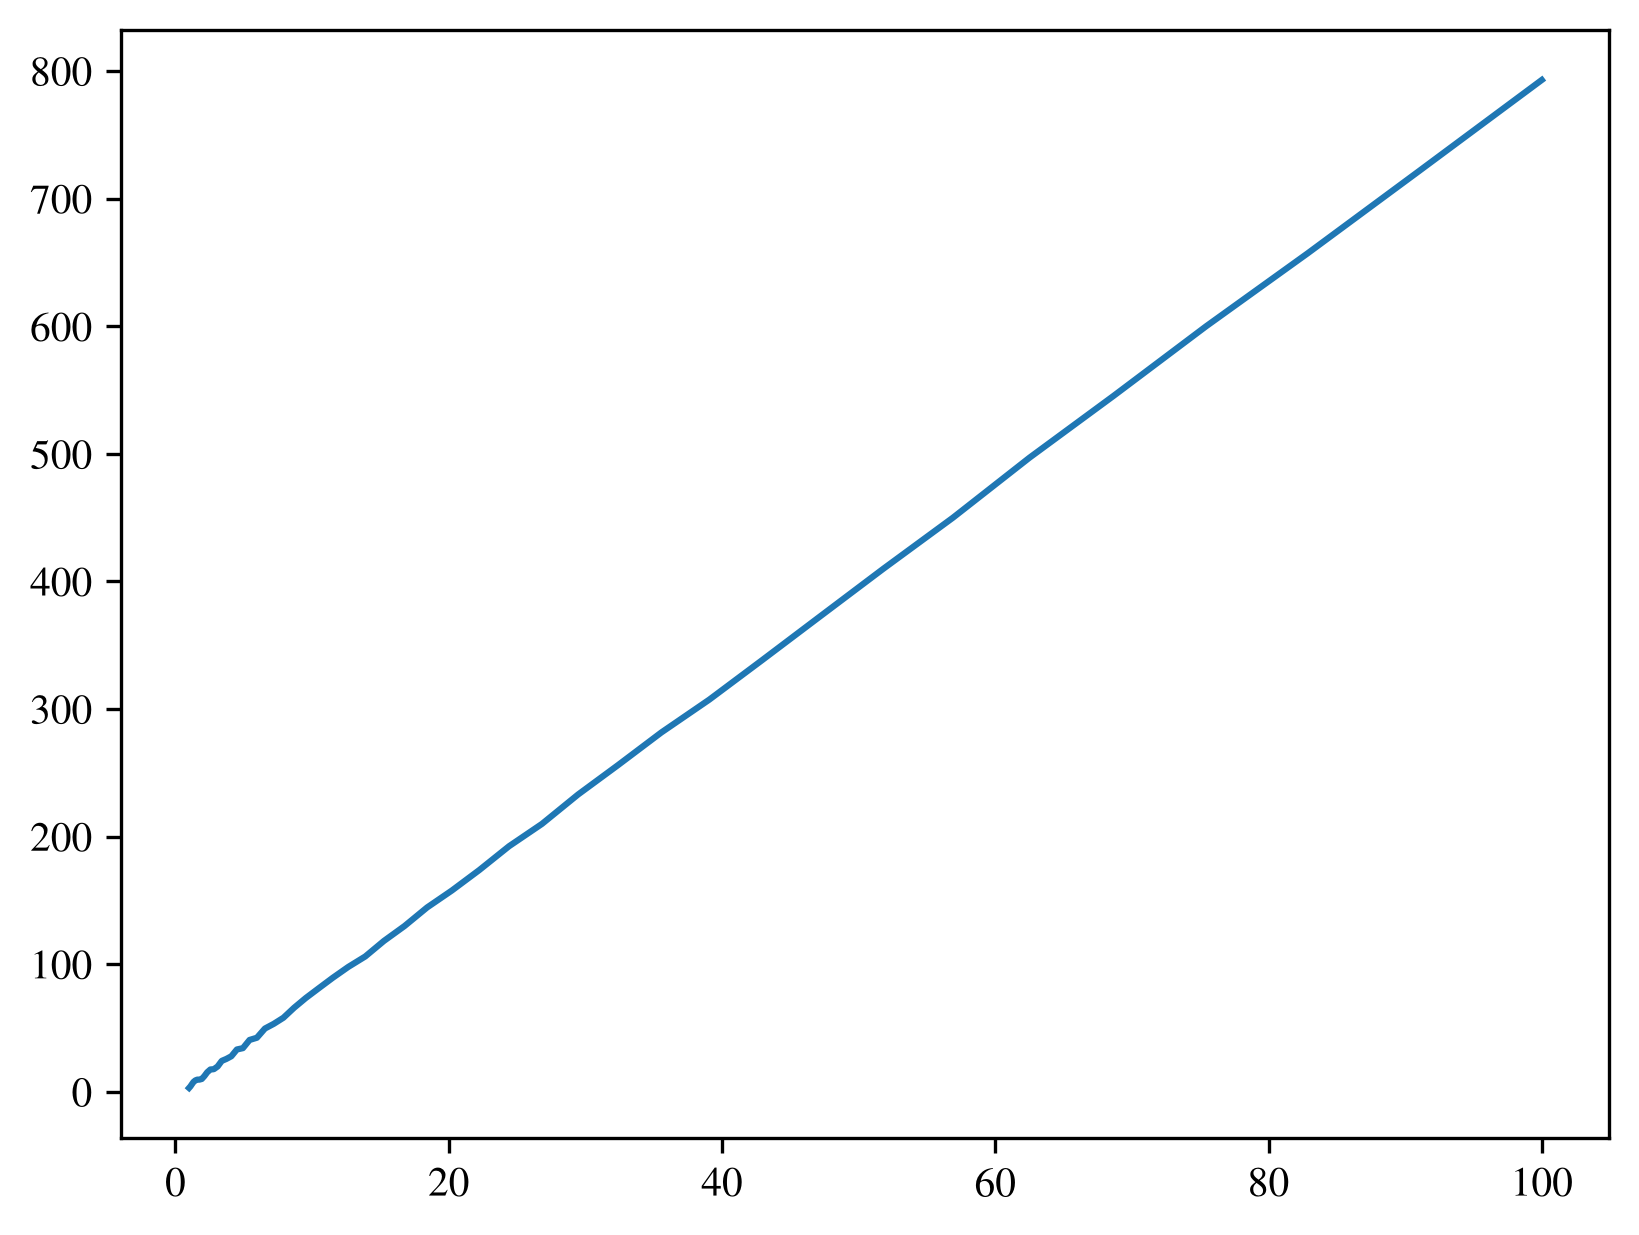

In [325]:
plt.plot(rmaxes, ys_airy)

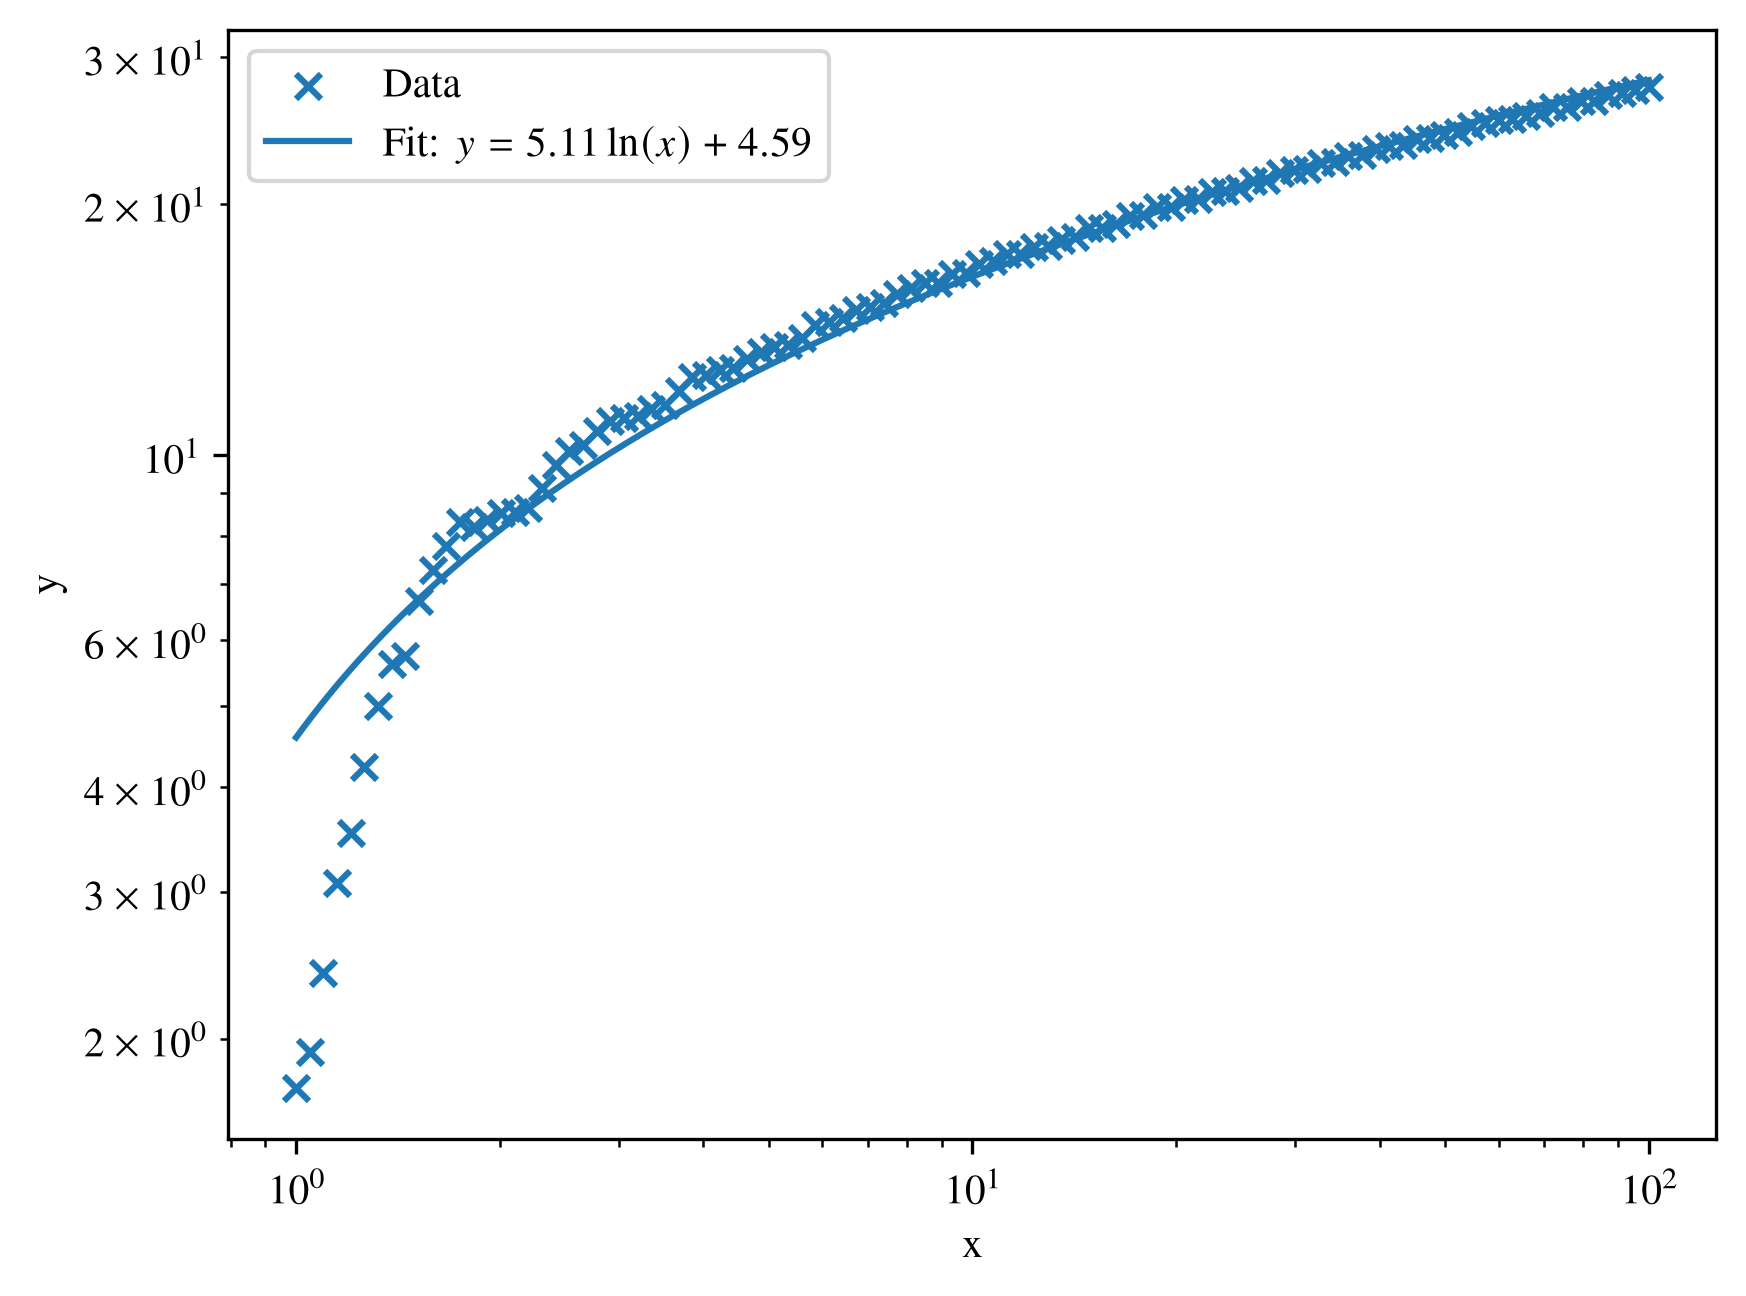

In [56]:
# fit logarithmic
A, B = np.polyfit(np.log(rmaxes), ys_square, 1)

# Smooth x-values for plotting the fitted curve
x_model = np.geomspace(rmaxes.min(), rmaxes.max(), 500)
y_model = A * np.log(x_model) + B

plt.scatter(rmaxes, ys_square, label="Data", marker='x')
plt.plot(x_model, y_model, label=fr"Fit: $y={A:.3g}\ln(x)+{B:.3g}$")
plt.xlabel("x")
plt.ylabel("y")
plt.yscale('log')
plt.xscale('log')
plt.legend()
plt.show()

In [297]:
m, log_A = np.polyfit(np.log(rmaxes[-5:]), np.log(ys_airy[-5:]), deg=1)
A = np.exp(log_A)

# y_fit = A * x**m

In [321]:
A, B = np.polyfit(rmaxes[-7:], ys_airy[-7:], deg=1)

In [322]:
A

Array(7.92663465, dtype=float64)

In [323]:
m

Array(0.99285248, dtype=float64)

In [324]:
B

Array(0.66573823, dtype=float64)

In [340]:
np.exp(np.mean(np.log(ys_nircam[-5:] / rmaxes[-5:])))

Array(5.60054601, dtype=float64)

In [231]:
ys_airy[:-30]

Array([ 3.10959723,  4.32003399,  6.03285936,  7.8039144 ,  8.98165914,
        9.61746021,  9.65237139, 10.1570896 , 12.41073068, 15.41586332,
       17.56673205, 17.82907427, 19.92940046, 24.31605288, 25.84383653,
       27.95671779, 33.2464402 , 34.31699102, 40.72581175, 42.45309161],      dtype=float64)

In [ ]:
ys_

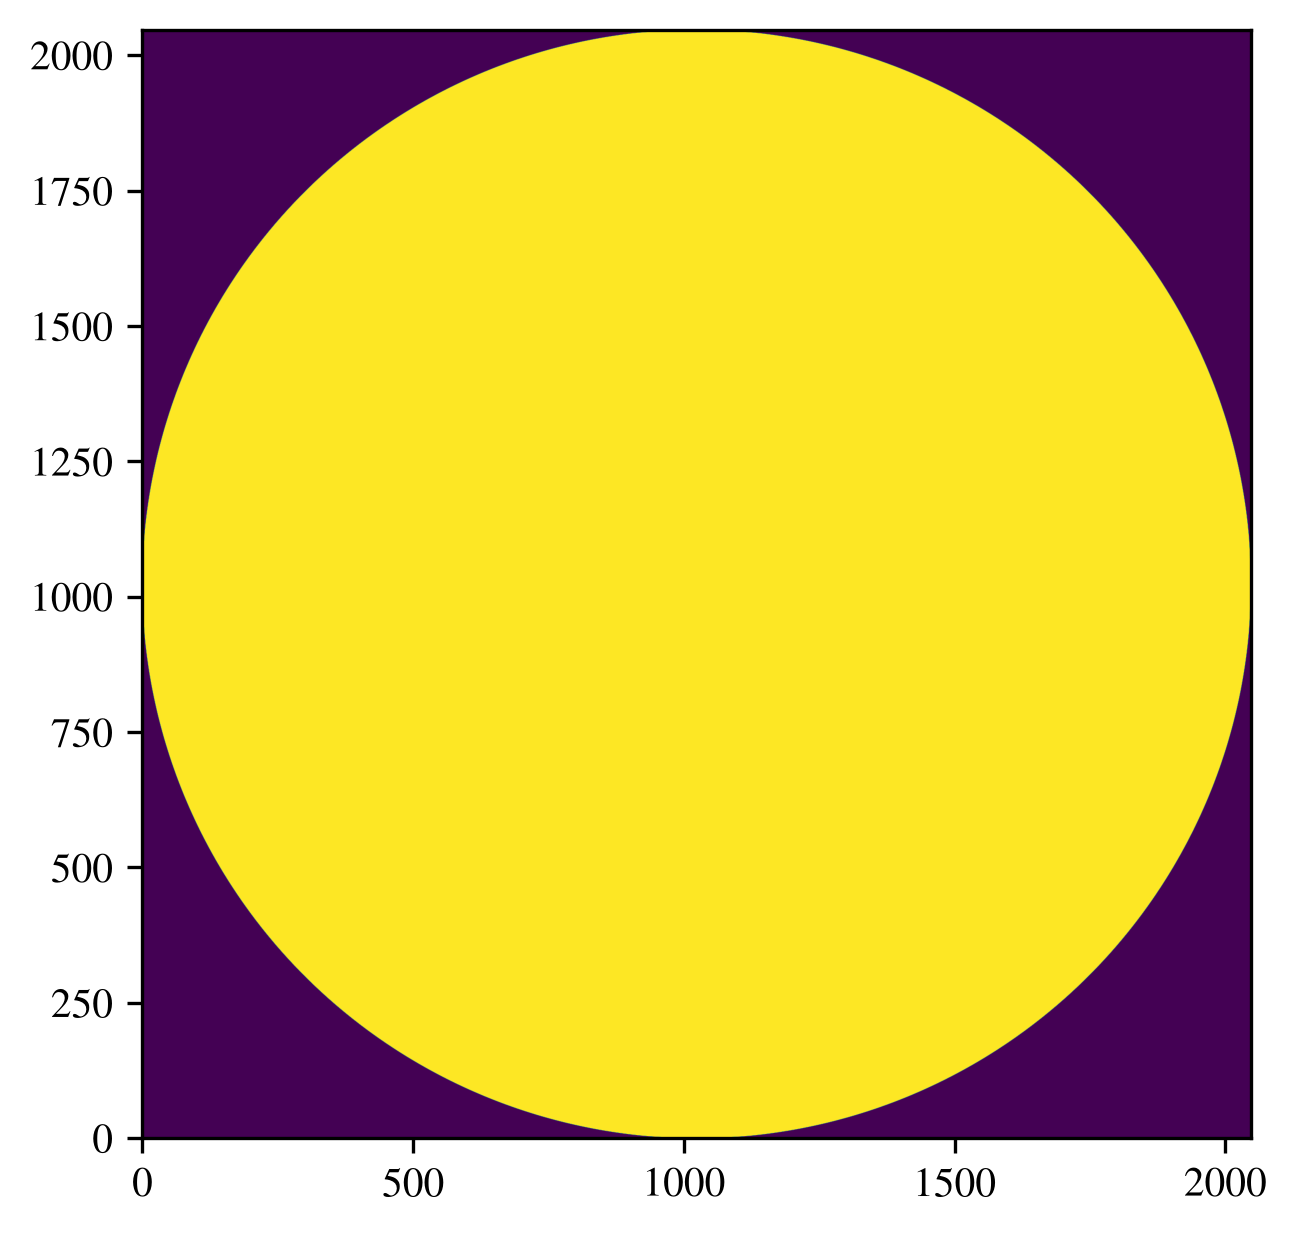

In [126]:
plt.imshow(aperture)

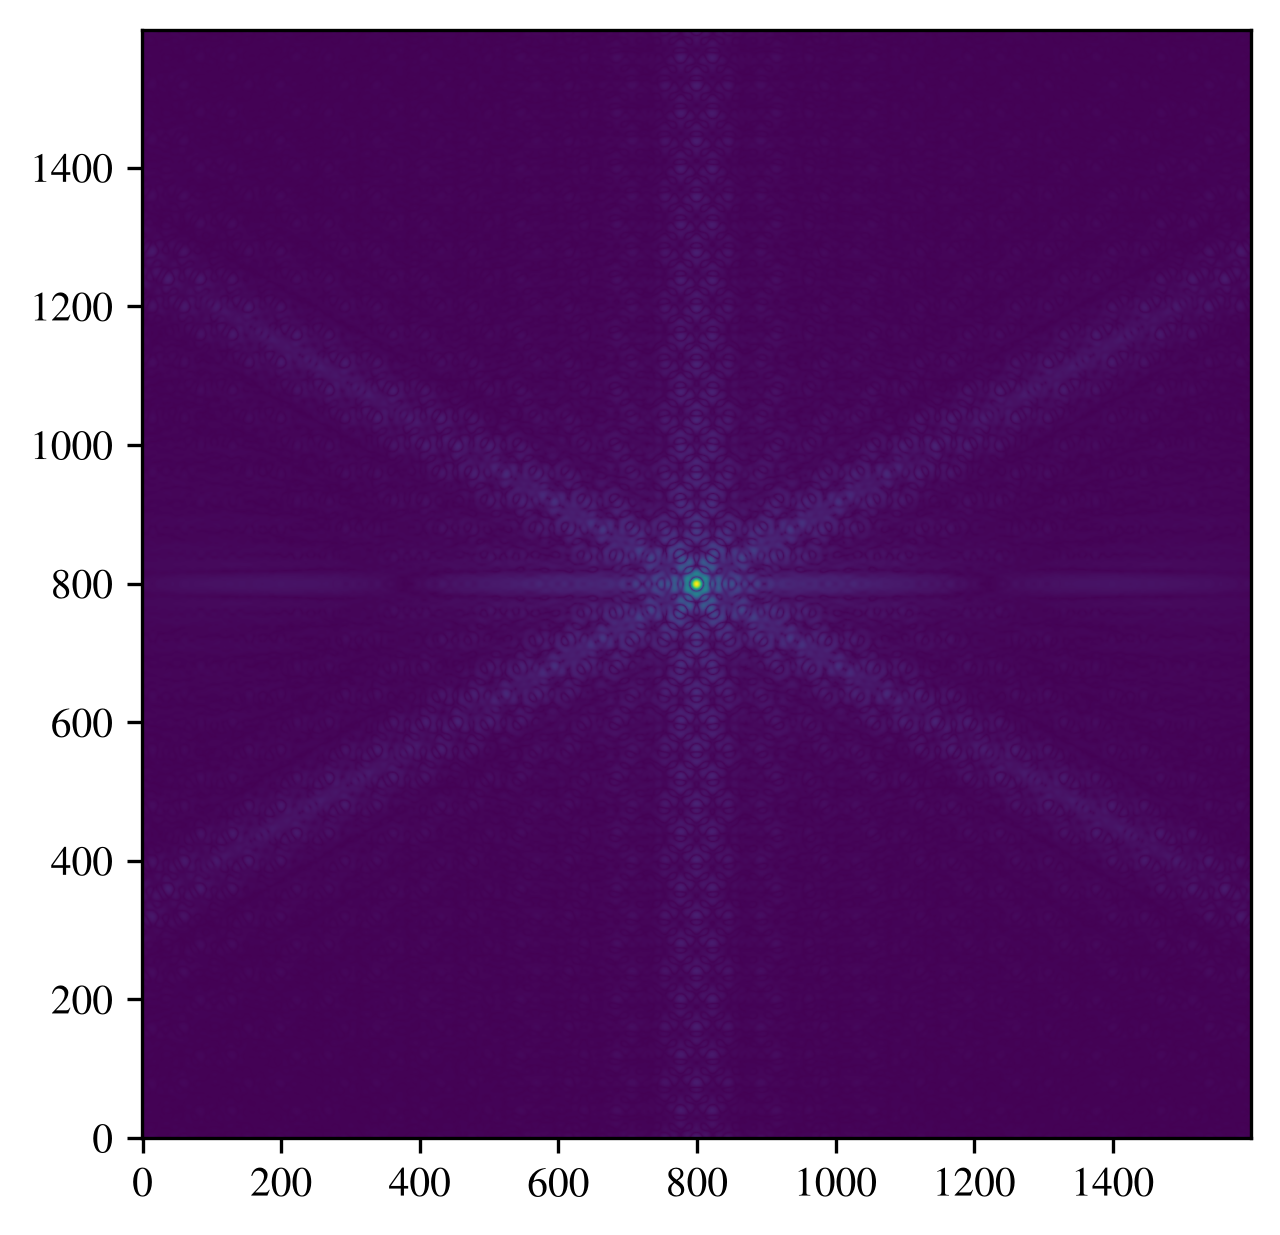

In [60]:
plt.imshow(telescope_nircam.model()**0.25)
plt.show()